# Estudo de Caso 9.5 — Resfriamento de Óleo Hidráulico em Usina Hidrelétrica

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 9 — Trocadores de Calor |
| **Nível** | Ambos (Graduação e Pós-Graduação) |
| **Tempo estimado** | 90 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | LMTD (contracorrente) + análise de incrustação |
| **Bibliografia** | Incropera et al. (2017), Cap. 11; Kakaç, Liu & Majumdar (2012), Cap. 3; Lugon Jr. (2026), Cap. 9 |

---

## 📋 Resumo

Dimensionamos o sistema de resfriamento do óleo hidráulico da estação de comando de uma usina hidrelétrica de pequeno porte (5 MW). O óleo, submetido a ciclos severos de pressurização nos servomotores das turbinas, é resfriado de 60 °C para 45 °C utilizando água bruta captada do rio em um trocador de calor de placas em contracorrente. O estudo aborda o balanço de energia, o cálculo da LMTD, o dimensionamento da área de troca, a verificação hidráulica das velocidades nos canais, a comparação com trocador casco-tubo e a análise de sensibilidade à incrustação (fouling).

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Aplicar** o balanço de energia em trocador de calor com dois fluidos sem mudança de fase
2. **Calcular** a LMTD para configuração contracorrente pura (F = 1)
3. **Dimensionar** a área de troca e o número de placas de um trocador de calor
4. **Verificar** as velocidades dos fluidos nos canais e a queda de pressão associada
5. **Comparar** o desempenho de trocadores de placas e casco-tubo para a mesma aplicação
6. **Analisar** a sensibilidade do dimensionamento à incrustação ao longo do tempo
7. **Interpretar** os resultados à luz das normas de operação de usinas hidrelétricas

---

## ⚙️ Seção 0: Configuração Inicial

In [29]:
# ============================================================
# CONFIGURAÇÃO INICIAL — Importação de bibliotecas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown
import time

# Forçar fonte com suporte completo a glifos Unicode
plt.rcParams['font.family'] = 'DejaVu Sans'

# Estilo dos gráficos (padrão do guia)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('✅ Ambiente configurado com sucesso')
print(f'📦 NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__}')

✅ Ambiente configurado com sucesso
📦 NumPy 1.26.4 | Matplotlib 3.10.1


---

## 🌊 Seção 1: Parâmetros do Problema

### Contexto Industrial

Uma usina hidrelétrica de pequeno porte (5 MW) possui um sistema de óleo hidráulico para acionamento dos servomotores das turbinas. O óleo é submetido a ciclos severos de pressurização e despressurização, o que eleva sua temperatura. Para garantir a viscosidade adequada e proteger os componentes, o óleo é resfriado em um trocador de calor de placas antes de retornar ao reservatório.

> 💡 **Observação:** A temperatura do óleo hidráulico deve ser mantida entre 40 °C e 50 °C para garantir viscosidade ideal. Temperaturas acima de 60 °C aceleram a oxidação do óleo e reduzem sua vida útil.

### Tabela de Parâmetros

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|------:|:-------:|
| **Fluido quente (óleo hidráulico)** | | | |
| Vazão mássica | $\dot{m}_h$ | 15,0 | kg/s |
| Calor específico | $c_{p,h}$ | 2000 | J/(kg·K) |
| Massa específica | $\rho_h$ | 870 | kg/m³ |
| Temperatura de entrada | $T_{h,in}$ | 60 | °C |
| Temperatura de saída | $T_{h,out}$ | 45 | °C |
| **Fluido frio (água do rio)** | | | |
| Vazão mássica | $\dot{m}_c$ | 12,0 | kg/s |
| Calor específico | $c_{p,c}$ | 4180 | J/(kg·K) |
| Massa específica | $\rho_c$ | 1000 | kg/m³ |
| Temperatura de entrada | $T_{c,in}$ | 20 | °C |
| **Trocador de placas** | | | |
| Coeficiente global limpo | $U_{limpo}$ | 600 | W/(m²·K) |
| Área efetiva por placa | $A_{placa}$ | 1,2 | m² |
| Largura efetiva da placa | $L_{placa}$ | 0,5 | m |
| Espaçamento entre placas | $\delta$ | 3 | mm |
| Fator de correção LMTD | $F$ | 1,0 | – |
| **Incrustação** | | | |
| Fator de incrustação (óleo) | $R_{f,oleo}$ | 0,0001 | m²·K/W |
| Fator de incrustação (água) | $R_{f,agua}$ | 0,0004 | m²·K/W |

In [30]:
# ============================================================
# DADOS DO PROBLEMA
# ============================================================

# --- Fluido quente: óleo hidráulico ---
m_dot_h = 15.0       # Vazão mássica do óleo [kg/s]
cp_h = 2000.0        # Calor específico do óleo [J/(kg·K)]
rho_h = 870.0        # Massa específica do óleo [kg/m³]
Th_in = 60.0         # Temperatura de entrada do óleo [°C]
Th_out = 45.0        # Temperatura de saída do óleo [°C]

# --- Fluido frio: água do rio ---
m_dot_c = 12.0       # Vazão mássica da água [kg/s]
cp_c = 4180.0        # Calor específico da água [J/(kg·K)]
rho_c = 1000.0       # Massa específica da água [kg/m³]
Tc_in = 20.0         # Temperatura de entrada da água [°C]

# --- Geometria e parâmetros do trocador de placas ---
U_limpo = 600.0      # Coeficiente global limpo [W/(m²·K)]
A_placa = 1.2        # Área efetiva por placa [m²]
L_placa = 0.5        # Largura efetiva da placa [m]
delta = 0.003        # Espaçamento entre placas [m]
F_placas = 1.0       # Fator de correção LMTD (contracorrente pura) [-]

# --- Fatores de incrustação ---
Rf_oleo = 0.0001     # Fator de incrustação do óleo [m²·K/W]
Rf_agua = 0.0004     # Fator de incrustação da água [m²·K/W]
Rf_total = Rf_oleo + Rf_agua  # Fator total [m²·K/W]

print('📏 Parâmetros do problema:')
print(f'  • Óleo: ṁ_h={m_dot_h} kg/s, T_in={Th_in}°C, T_out={Th_out}°C')
print(f'  • Água: ṁ_c={m_dot_c} kg/s, T_in={Tc_in}°C')
print(f'  • Trocador: U_limpo={U_limpo} W/(m²·K), A_placa={A_placa} m²')
print(f'  • Incrustação total: Rf={Rf_total:.5f} m²·K/W')

📏 Parâmetros do problema:
  • Óleo: ṁ_h=15.0 kg/s, T_in=60.0°C, T_out=45.0°C
  • Água: ṁ_c=12.0 kg/s, T_in=20.0°C
  • Trocador: U_limpo=600.0 W/(m²·K), A_placa=1.2 m²
  • Incrustação total: Rf=0.00050 m²·K/W


---

## 🔬 Seção 2: Verificação — Balanço de Energia

Antes do dimensionamento, verificamos a consistência do balanço de energia.

### Carga térmica do óleo (fluido quente)

$$\dot{Q} = \dot{m}_h \cdot c_{p,h} \cdot (T_{h,in} - T_{h,out})$$

### Temperatura de saída da água (fluido frio)

$$T_{c,out} = T_{c,in} + \frac{\dot{Q}}{\dot{m}_c \cdot c_{p,c}}$$

### Verificação da razão de capacidades térmicas

$$C_h = \dot{m}_h \cdot c_{p,h}, \quad C_c = \dot{m}_c \cdot c_{p,c}$$

Se $C_h < C_c$, o óleo é o fluido de capacidade mínima.

> 📖 **Referência:** Incropera et al. (2017), Cap. 11, Seção 11.2.

In [31]:
# ============================================================
# VERIFICAÇÃO — BALANÇO DE ENERGIA
# ============================================================

t_inicio = time.time()

# Carga térmica a ser removida do óleo
Q = m_dot_h * cp_h * (Th_in - Th_out)   # [W]

# Temperatura de saída da água (balanço global: Q_h = Q_c)
Tc_out = Tc_in + Q / (m_dot_c * cp_c)   # [°C]

# Capacidades térmicas
C_h = m_dot_h * cp_h   # [W/K]
C_c = m_dot_c * cp_c   # [W/K]

# Verificação: Tc_out deve ser menor que Th_in (consistência termodinâmica)
assert Tc_out < Th_in, f'Erro: Tc_out={Tc_out:.1f}°C >= Th_in={Th_in}°C'
assert Tc_out > Tc_in, f'Erro: Tc_out={Tc_out:.1f}°C <= Tc_in={Tc_in}°C'

t_cpu_balanco = time.time() - t_inicio

print('🔬 VERIFICAÇÃO — BALANÇO DE ENERGIA')
print('=' * 50)
print(f'  • Carga térmica: Q = {Q:.0f} W = {Q/1000:.2f} kW')
print(f'  • T_c,out = {Tc_out:.2f} °C')
print(f'  • Razão de capacidades: C_h/C_c = {C_h/C_c:.2f}')
print(f'  • Óleo é o fluido de capacidade mínima: {C_h < C_c}')
print(f'  • Verificação: Tc_in < Tc_out < Th_in ✓')
print(f'  ⏱️ Tempo de CPU: {t_cpu_balanco:.6f} s')

🔬 VERIFICAÇÃO — BALANÇO DE ENERGIA
  • Carga térmica: Q = 450000 W = 450.00 kW
  • T_c,out = 28.97 °C
  • Razão de capacidades: C_h/C_c = 0.60
  • Óleo é o fluido de capacidade mínima: True
  • Verificação: Tc_in < Tc_out < Th_in ✓
  ⏱️ Tempo de CPU: 0.000000 s


---

## 📐 Seção 3: Formulação Matemática

### 3.1 LMTD para configuração contracorrente

Para um trocador de calor em contracorrente pura, a diferença média logarítmica de temperatura é:

$$\Delta T_{lm} = \frac{\Delta T_1 - \Delta T_2}{\ln(\Delta T_1 / \Delta T_2)}$$

onde:
- $\Delta T_1 = T_{h,in} - T_{c,out}$ (extremidade quente)
- $\Delta T_2 = T_{h,out} - T_{c,in}$ (extremidade fria)

### 3.2 Área de troca necessária

$$A = \frac{\dot{Q}}{U \cdot F \cdot \Delta T_{lm}}$$

onde:
- $U$ = coeficiente global de transferência de calor [W/(m²·K)]
- $F$ = fator de correção da LMTD (para contracorrente pura, $F = 1$)
- $A$ = área total de troca [m²]

### 3.3 Coeficiente global com incrustação

$$\frac{1}{U_{sujo}} = \frac{1}{U_{limpo}} + R_{f,total}$$

onde:
- $R_{f,total} = R_{f,oleo} + R_{f,agua}$ = fator total de incrustação [m²·K/W]

### 3.4 Número de placas

$$N_{placas} = \left\lceil \frac{A}{A_{placa}} \right\rceil$$

> 📖 **Referência:** Incropera et al. (2017), Cap. 11, Seções 11.3–11.4; Kakaç, Liu & Majumdar (2012), Cap. 3.

---

## ⚡ Seção 4: Critério de Projeto e Verificação Hidráulica

> 💡 **Observação:** Neste problema de regime permanente, não se aplica a condição CFL. Os critérios de adequação são:

1. **Velocidade nos canais:** Para trocadores de placas, a velocidade recomendada é 0,3 a 1,5 m/s para garantir boa transferência de calor sem queda de pressão excessiva.

2. **Razão de capacidades:** $C_h/C_c < 1$ indica que o óleo é o fluido limitante.

3. **Fator de correção LMTD:** Para contracorrente pura, $F = 1$. Para configurações com múltiplas passadas, $F < 1$.

### Verificação hidráulica

A velocidade em cada canal é:

$$v = \frac{\dot{m}}{\rho \cdot N_{canais} \cdot A_{canal}}$$

onde:
- $N_{canais}$ = número de canais por fluido
- $A_{canal} = L_{placa} \cdot \delta$ = área de seção transversal de um canal [m²]

---

## 🌪️ Seção 5: Condições de Entrada (Forçamento Térmico)

Neste problema de regime permanente, o forçamento é dado pelas condições de entrada dos fluidos:

- **Óleo:** $\dot{m}_h = 15$ kg/s a $T_{h,in} = 60$ °C
- **Água:** $\dot{m}_c = 12$ kg/s a $T_{c,in} = 20$ °C

A carga térmica a ser removida é:

$$\dot{Q} = \dot{m}_h \cdot c_{p,h} \cdot (T_{h,in} - T_{h,out}) = 15 \times 2000 \times 15 = 450 \text{ kW}$$

> 💡 **Observação:** A temperatura da água do rio pode variar sazonalmente (18 °C no inverno a 28 °C no verão), o que afeta diretamente a LMTD e a área necessária.

---

## 🧮 Seção 6: Implementação Numérica

In [32]:
# ============================================================
# FUNÇÃO: Cálculo da LMTD
# ============================================================

def calcular_LMTD(Th_in, Th_out, Tc_in, Tc_out):
    """
    Calcula a LMTD para configuração contracorrente.

    Parameters
    ----------
    Th_in : float
        Temperatura de entrada do fluido quente [°C].
    Th_out : float
        Temperatura de saída do fluido quente [°C].
    Tc_in : float
        Temperatura de entrada do fluido frio [°C].
    Tc_out : float
        Temperatura de saída do fluido frio [°C].

    Returns
    -------
    float
        LMTD [°C].

    Notes
    -----
    Para contracorrente pura: F = 1.
    """
    dT1 = Th_in - Tc_out   # Extremidade quente
    dT2 = Th_out - Tc_in   # Extremidade fria

    if np.isclose(dT1, dT2):
        return dT1
    return (dT1 - dT2) / np.log(dT1 / dT2)

In [33]:
# ============================================================
# FUNÇÃO: Dimensionamento do trocador
# ============================================================

def dimensionar_trocador(Q, U, F, LMTD, A_placa):
    """
    Dimensiona a área de troca e o número de placas.

    Parameters
    ----------
    Q : float
        Carga térmica [W].
    U : float
        Coeficiente global [W/(m²·K)].
    F : float
        Fator de correção da LMTD [-].
    LMTD : float
        Diferença média logarítmica de temperatura [°C].
    A_placa : float
        Área efetiva por placa [m²].

    Returns
    -------
    dict
        Dicionário com área necessária, número de placas e área instalada.
    """
    A_necessaria = Q / (U * F * LMTD)
    N_placas = int(np.ceil(A_necessaria / A_placa))
    A_instalada = N_placas * A_placa

    return {
        'A_necessaria': A_necessaria,
        'N_placas': N_placas,
        'A_instalada': A_instalada,
        'margem': (A_instalada - A_necessaria) / A_necessaria * 100
    }

In [34]:
# ============================================================
# DIMENSIONAMENTO — CASO BASE (trocador limpo)
# ============================================================

t_inicio = time.time()

# Cálculo da LMTD
LMTD = calcular_LMTD(Th_in, Th_out, Tc_in, Tc_out)

# Dimensionamento
resultado_limpo = dimensionar_trocador(Q, U_limpo, F_placas, LMTD, A_placa)

t_cpu_dim = time.time() - t_inicio

print('🧮 DIMENSIONAMENTO — TROCADOR LIMPO')
print('=' * 50)
print(f'  • LMTD = {LMTD:.2f} °C')
print(f'  • Área necessária: A = {resultado_limpo["A_necessaria"]:.2f} m²')
print(f'  • Número de placas: N = {resultado_limpo["N_placas"]}')
print(f'  • Área instalada: A_inst = {resultado_limpo["A_instalada"]:.2f} m²')
print(f'  • Margem de projeto: {resultado_limpo["margem"]:.1f}%')
print(f'  ⏱️ Tempo de CPU: {t_cpu_dim:.6f} s')

🧮 DIMENSIONAMENTO — TROCADOR LIMPO
  • LMTD = 27.91 °C
  • Área necessária: A = 26.88 m²
  • Número de placas: N = 23
  • Área instalada: A_inst = 27.60 m²
  • Margem de projeto: 2.7%
  ⏱️ Tempo de CPU: 0.000000 s


In [35]:
# ============================================================
# VERIFICAÇÃO HIDRÁULICA — Velocidades nos canais
# ============================================================

N_placas_base = resultado_limpo['N_placas']

# Número de canais por fluido
N_canais_total = N_placas_base - 1
N_canais_fluido = N_canais_total // 2   # Metade para óleo, metade para água

# Área de seção transversal de um canal
A_canal = L_placa * delta   # [m²]

# Velocidades
v_oleo = (m_dot_h / rho_h) / (N_canais_fluido * A_canal)   # [m/s]
v_agua = (m_dot_c / rho_c) / (N_canais_fluido * A_canal)   # [m/s]

print('⚡ VERIFICAÇÃO HIDRÁULICA')
print('=' * 50)
print(f'  • Número de placas: {N_placas_base}')
print(f'  • Canais por fluido: {N_canais_fluido}')
print(f'  • Área do canal: A_canal = {A_canal*1e4:.2f} cm²')
print(f'  • Velocidade do óleo: v_oleo = {v_oleo:.2f} m/s')
print(f'  • Velocidade da água: v_agua = {v_agua:.2f} m/s')
print(f'  • Faixa recomendada: 0,3 a 1,5 m/s')

if 0.3 <= v_oleo <= 1.5:
    print(f'  ✓ Velocidade do óleo dentro da faixa')
else:
    print(f'  ⚠️ Velocidade do óleo fora da faixa')

if 0.3 <= v_agua <= 1.5:
    print(f'  ✓ Velocidade da água dentro da faixa')
else:
    print(f'  ⚠️ Velocidade da água fora da faixa')

⚡ VERIFICAÇÃO HIDRÁULICA
  • Número de placas: 23
  • Canais por fluido: 11
  • Área do canal: A_canal = 15.00 cm²
  • Velocidade do óleo: v_oleo = 1.04 m/s
  • Velocidade da água: v_agua = 0.73 m/s
  • Faixa recomendada: 0,3 a 1,5 m/s
  ✓ Velocidade do óleo dentro da faixa
  ✓ Velocidade da água dentro da faixa


In [36]:
# ============================================================
# COMPARAÇÃO COM TROCADOR CASCO-TUBO
# ============================================================

# Coeficiente global típico para óleo-água em casco-tubo
U_casco_tubo = 300.0   # [W/(m²·K)]
F_casco_tubo = 0.90    # Fator de correção (1 casco, 2 passes de tubos)

A_casco_tubo = Q / (U_casco_tubo * F_casco_tubo * LMTD)

razao_areas = A_casco_tubo / resultado_limpo['A_necessaria']

print('🧮 COMPARAÇÃO — TROCADOR CASCO-TUBO')
print('=' * 50)
print(f'  • U_casco_tubo = {U_casco_tubo} W/(m²·K)')
print(f'  • F_casco_tubo = {F_casco_tubo}')
print(f'  • Área necessária: A = {A_casco_tubo:.2f} m²')
print(f'  • Razão de áreas (casco-tubo / placas): {razao_areas:.2f}×')
print(f'\n  💡 O trocador de placas é {razao_areas:.1f}× mais compacto')

🧮 COMPARAÇÃO — TROCADOR CASCO-TUBO
  • U_casco_tubo = 300.0 W/(m²·K)
  • F_casco_tubo = 0.9
  • Área necessária: A = 59.72 m²
  • Razão de áreas (casco-tubo / placas): 2.22×

  💡 O trocador de placas é 2.2× mais compacto


---

## 📊 Seção 7: Visualização

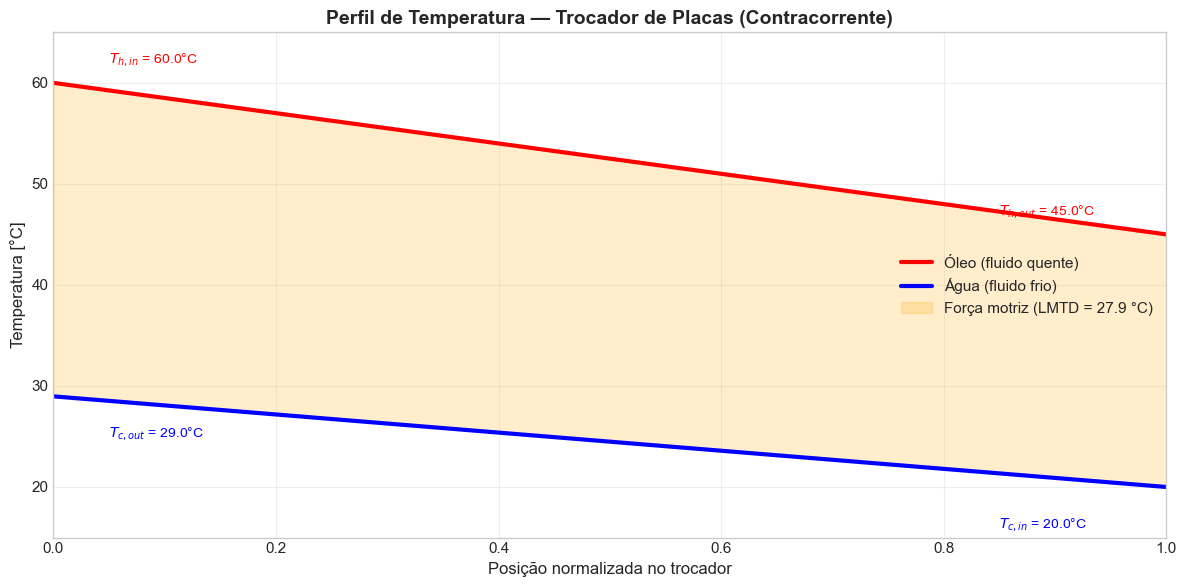

In [37]:
# ============================================================
# GRÁFICO — Perfil de temperatura no trocador
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

# Posição normalizada (0 = entrada do óleo / saída da água)
x = np.linspace(0, 1, 100)

# Perfil do óleo (resfriamento linear)
T_oleo = Th_in - (Th_in - Th_out) * x

# Perfil da água (aquecimento linear)
T_agua = Tc_out - (Tc_out - Tc_in) * x

ax.plot(x, T_oleo, 'r-', linewidth=3, label='Óleo (fluido quente)')
ax.plot(x, T_agua, 'b-', linewidth=3, label='Água (fluido frio)')

# Preenchimento da força motriz
ax.fill_between(x, T_agua, T_oleo, color='orange', alpha=0.2,
                label=f'Força motriz (LMTD = {LMTD:.1f} °C)')

# Anotações
ax.annotate(f'$T_{{h,in}}$ = {Th_in}°C', xy=(0, Th_in),
            xytext=(0.05, Th_in + 2), fontsize=10, color='red')
ax.annotate(f'$T_{{h,out}}$ = {Th_out}°C', xy=(1, Th_out),
            xytext=(0.85, Th_out + 2), fontsize=10, color='red')
ax.annotate(f'$T_{{c,out}}$ = {Tc_out:.1f}°C', xy=(0, Tc_out),
            xytext=(0.05, Tc_out - 4), fontsize=10, color='blue')
ax.annotate(f'$T_{{c,in}}$ = {Tc_in}°C', xy=(1, Tc_in),
            xytext=(0.85, Tc_in - 4), fontsize=10, color='blue')

ax.set_xlabel('Posição normalizada no trocador', fontsize=12)
ax.set_ylabel('Temperatura [°C]', fontsize=12)
ax.set_title('Perfil de Temperatura — Trocador de Placas (Contracorrente)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='center right')
ax.set_xlim(0, 1)
ax.set_ylim(15, 65)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - O perfil de temperatura é linear porque não há mudança de fase e os calores específicos são constantes.
> - Na configuração contracorrente, a diferença de temperatura é mais uniforme ao longo do trocador, maximizando a LMTD.
> - A temperatura de saída da água (28,97 °C) permanece bem abaixo da temperatura de entrada do óleo (60 °C), garantindo força motriz em toda a extensão.

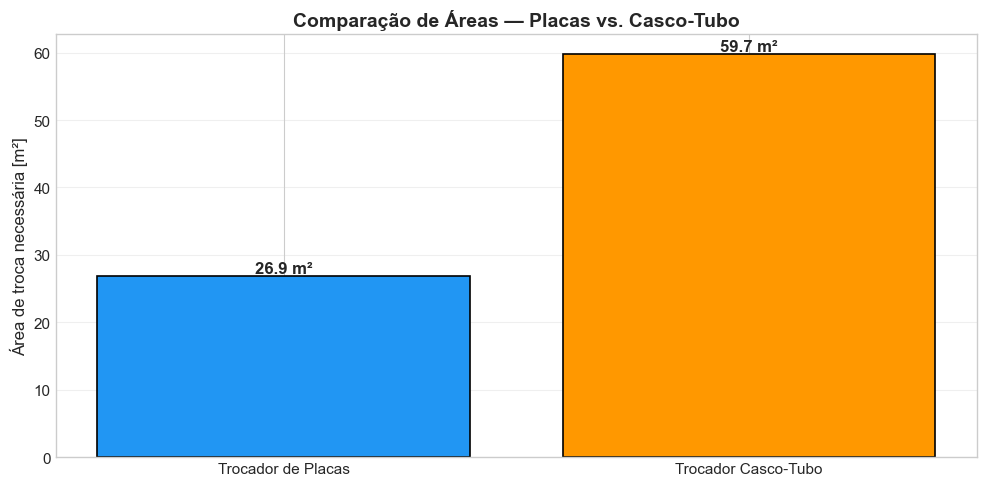

In [38]:
# ============================================================
# GRÁFICO — Comparação de áreas (placas vs. casco-tubo)
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))

tipos = ['Trocador de Placas', 'Trocador Casco-Tubo']
areas = [resultado_limpo['A_necessaria'], A_casco_tubo]
cores = ['#2196F3', '#FF9800']

bars = ax.bar(tipos, areas, color=cores, edgecolor='black', linewidth=1.2)

for bar, val in zip(bars, areas):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f} m²', ha='center', fontsize=12, fontweight='bold')

ax.set_ylabel('Área de troca necessária [m²]', fontsize=12)
ax.set_title('Comparação de Áreas — Placas vs. Casco-Tubo',
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - O trocador de placas requer ~2,2× menos área que o casco-tubo para a mesma aplicação.
> - Isso se deve ao maior coeficiente global (turbulência induzida pelas placas) e ao fator de correção $F = 1$.
> - Em usinas hidrelétricas, a compacidade do trocador de placas é uma vantagem significativa.

---

## 📈 Seção 8: Análise Quantitativa

In [39]:
# ============================================================
# ANÁLISE DE INCRUSTAÇÃO (FOULING)
# ============================================================

# Coeficiente global com incrustação
U_sujo = 1.0 / (1.0 / U_limpo + Rf_total)   # [W/(m²·K)]

# Nova área necessária com incrustação
resultado_sujo = dimensionar_trocador(Q, U_sujo, F_placas, LMTD, A_placa)

# Redução do coeficiente global
reducao_U = (1 - U_sujo / U_limpo) * 100   # [%]

print('📈 ANÁLISE DE INCRUSTAÇÃO')
print('=' * 50)
print(f'  • Rf_total = {Rf_total:.5f} m²·K/W')
print(f'  • U_limpo = {U_limpo:.0f} W/(m²·K)')
print(f'  • U_sujo = {U_sujo:.2f} W/(m²·K)')
print(f'  • Redução de U: {reducao_U:.1f}%')
print(f'  • Área necessária (sujo): {resultado_sujo["A_necessaria"]:.2f} m²')
print(f'  • Número de placas (sujo): {resultado_sujo["N_placas"]}')
print(f'  • Área instalada (sujo): {resultado_sujo["A_instalada"]:.2f} m²')

📈 ANÁLISE DE INCRUSTAÇÃO
  • Rf_total = 0.00050 m²·K/W
  • U_limpo = 600 W/(m²·K)
  • U_sujo = 461.54 W/(m²·K)
  • Redução de U: 23.1%
  • Área necessária (sujo): 34.94 m²
  • Número de placas (sujo): 30
  • Área instalada (sujo): 36.00 m²


In [40]:
# ============================================================
# TABELA RESUMO DOS RESULTADOS
# ============================================================

dados_tabela = {
    'Grandeza': [
        'Carga térmica (Q)',
        'Temperatura de saída da água (Tc_out)',
        'LMTD',
        'Coeficiente global limpo (U_limpo)',
        'Coeficiente global sujo (U_sujo)',
        'Área necessária (limpo)',
        'Área necessária (sujo)',
        'Número de placas (limpo)',
        'Número de placas (sujo)',
        'Área instalada (limpo)',
        'Área instalada (sujo)',
        'Velocidade do óleo',
        'Velocidade da água',
        'Área casco-tubo',
        'Razão de áreas (CT/placas)'
    ],
    'Valor': [
        f'{Q/1000:.2f}',
        f'{Tc_out:.2f}',
        f'{LMTD:.2f}',
        f'{U_limpo:.0f}',
        f'{U_sujo:.2f}',
        f'{resultado_limpo["A_necessaria"]:.2f}',
        f'{resultado_sujo["A_necessaria"]:.2f}',
        f'{resultado_limpo["N_placas"]}',
        f'{resultado_sujo["N_placas"]}',
        f'{resultado_limpo["A_instalada"]:.2f}',
        f'{resultado_sujo["A_instalada"]:.2f}',
        f'{v_oleo:.2f}',
        f'{v_agua:.2f}',
        f'{A_casco_tubo:.2f}',
        f'{razao_areas:.2f}'
    ],
    'Unidade': [
        'kW', '°C', '°C', 'W/(m²·K)', 'W/(m²·K)',
        'm²', 'm²', '–', '–', 'm²', 'm²',
        'm/s', 'm/s', 'm²', '–'
    ]
}

df_resumo = pd.DataFrame(dados_tabela)
display(Markdown(df_resumo.to_markdown(index=False)))

| Grandeza                              |   Valor | Unidade   |
|:--------------------------------------|--------:|:----------|
| Carga térmica (Q)                     |  450    | kW        |
| Temperatura de saída da água (Tc_out) |   28.97 | °C        |
| LMTD                                  |   27.91 | °C        |
| Coeficiente global limpo (U_limpo)    |  600    | W/(m²·K)  |
| Coeficiente global sujo (U_sujo)      |  461.54 | W/(m²·K)  |
| Área necessária (limpo)               |   26.88 | m²        |
| Área necessária (sujo)                |   34.94 | m²        |
| Número de placas (limpo)              |   23    | –         |
| Número de placas (sujo)               |   30    | –         |
| Área instalada (limpo)                |   27.6  | m²        |
| Área instalada (sujo)                 |   36    | m²        |
| Velocidade do óleo                    |    1.04 | m/s       |
| Velocidade da água                    |    0.73 | m/s       |
| Área casco-tubo                       |   59.72 | m²        |
| Razão de áreas (CT/placas)            |    2.22 | –         |

---

## 🔍 Seção 9: Análise de Sensibilidade

Analisamos a sensibilidade do dimensionamento a dois fatores críticos:
1. **Incrustação:** variação do fator de incrustação total
2. **Temperatura da água do rio:** variação sazonal

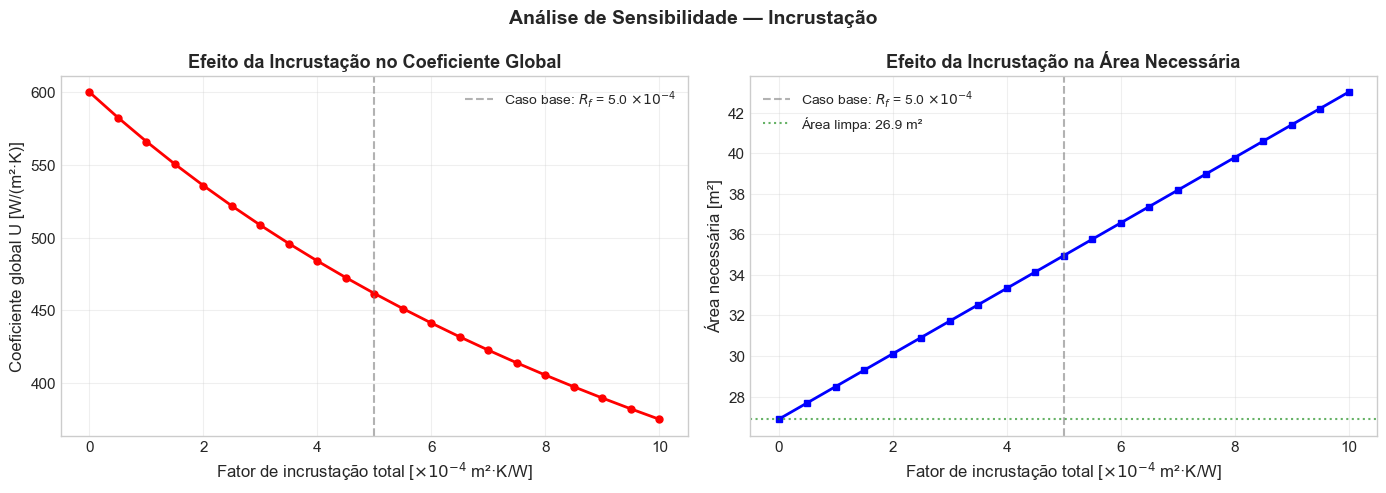

In [42]:
# ============================================================
# GRÁFICO — Sensibilidade à Incrustação (CORRIGIDO)
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Painel 1: Coeficiente global vs incrustação ---
ax1.plot(Rf_range * 1e4, U_sujo_range, 'r-o', linewidth=2, markersize=5)
ax1.axvline(Rf_total * 1e4, color='gray', linestyle='--', alpha=0.6,
            label=f'Caso base: $R_f$ = {Rf_total*1e4:.1f} $\\times 10^{{-4}}$')
ax1.set_xlabel('Fator de incrustação total [$\\times 10^{-4}$ m²·K/W]', fontsize=12)
ax1.set_ylabel('Coeficiente global U [W/(m²·K)]', fontsize=12)
ax1.set_title('Efeito da Incrustação no Coeficiente Global',
              fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# --- Painel 2: Área necessária vs incrustação ---
ax2.plot(Rf_range * 1e4, A_sujo_range, 'b-s', linewidth=2, markersize=5)
ax2.axvline(Rf_total * 1e4, color='gray', linestyle='--', alpha=0.6,
            label=f'Caso base: $R_f$ = {Rf_total*1e4:.1f} $\\times 10^{{-4}}$')
ax2.axhline(resultado_limpo['A_necessaria'], color='green', linestyle=':',
            alpha=0.6, label=f'Área limpa: {resultado_limpo["A_necessaria"]:.1f} m²')
ax2.set_xlabel('Fator de incrustação total [$\\times 10^{-4}$ m²·K/W]', fontsize=12)
ax2.set_ylabel('Área necessária [m²]', fontsize=12)
ax2.set_title('Efeito da Incrustação na Área Necessária',
              fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.suptitle('Análise de Sensibilidade — Incrustação', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A incrustação reduz o coeficiente global de forma não-linear: pequenos aumentos em $R_f$ causam reduções significativas em $U$.
> - Para o caso base ($R_f = 5×10^{-4}$ m²·K/W), a área necessária aumenta ~30% em relação ao trocador limpo.
> - Em usinas hidrelétricas, a água do rio pode conter sedimentos e matéria orgânica, acelerando a incrustação.

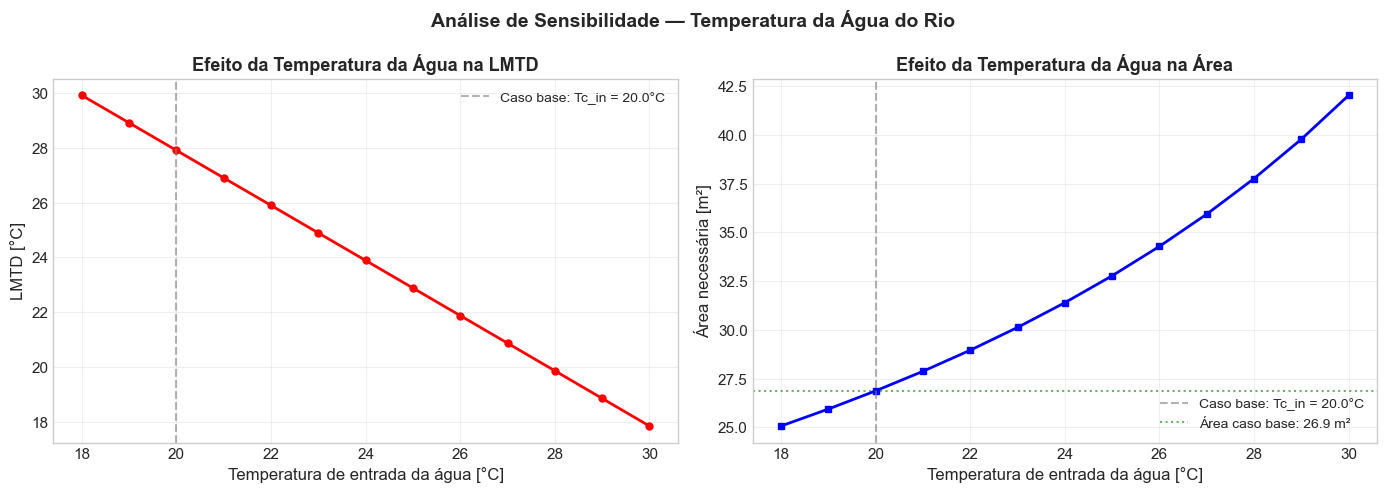


📊 Variação sazonal:
  • Inverno (Tc_in=18°C): LMTD=29.9°C, A=25.1 m²
  • Caso base (Tc_in=20°C): LMTD=27.9°C, A=26.9 m²
  • Verão (Tc_in=30°C): LMTD=17.8°C, A=42.0 m²


In [43]:
# ============================================================
# SENSIBILIDADE — Temperatura da água do rio
# ============================================================

# Variação sazonal da temperatura da água
Tc_in_range = np.linspace(18, 30, 13)   # [°C]
LMTD_range = []
A_range = []

for Tc_in_val in Tc_in_range:
    # Recalcular Tc_out para manter a mesma carga térmica
    Tc_out_val = Tc_in_val + Q / (m_dot_c * cp_c)
    LMTD_val = calcular_LMTD(Th_in, Th_out, Tc_in_val, Tc_out_val)
    A_val = Q / (U_limpo * F_placas * LMTD_val)
    LMTD_range.append(LMTD_val)
    A_range.append(A_val)

LMTD_range = np.array(LMTD_range)
A_range = np.array(A_range)

# Gráfico
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(Tc_in_range, LMTD_range, 'r-o', linewidth=2, markersize=5)
ax1.axvline(Tc_in, color='gray', linestyle='--', alpha=0.6,
            label=f'Caso base: Tc_in = {Tc_in}°C')
ax1.set_xlabel('Temperatura de entrada da água [°C]', fontsize=12)
ax1.set_ylabel('LMTD [°C]', fontsize=12)
ax1.set_title('Efeito da Temperatura da Água na LMTD',
              fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

ax2.plot(Tc_in_range, A_range, 'b-s', linewidth=2, markersize=5)
ax2.axvline(Tc_in, color='gray', linestyle='--', alpha=0.6,
            label=f'Caso base: Tc_in = {Tc_in}°C')
ax2.axhline(resultado_limpo['A_necessaria'], color='green', linestyle=':',
            alpha=0.6, label=f'Área caso base: {resultado_limpo["A_necessaria"]:.1f} m²')
ax2.set_xlabel('Temperatura de entrada da água [°C]', fontsize=12)
ax2.set_ylabel('Área necessária [m²]', fontsize=12)
ax2.set_title('Efeito da Temperatura da Água na Área',
              fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.suptitle('Análise de Sensibilidade — Temperatura da Água do Rio',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'\n📊 Variação sazonal:')
print(f'  • Inverno (Tc_in=18°C): LMTD={LMTD_range[0]:.1f}°C, A={A_range[0]:.1f} m²')
print(f'  • Caso base (Tc_in=20°C): LMTD={LMTD:.1f}°C, A={resultado_limpo["A_necessaria"]:.1f} m²')
print(f'  • Verão (Tc_in=30°C): LMTD={LMTD_range[-1]:.1f}°C, A={A_range[-1]:.1f} m²')

> 💡 **Observação:**
> - No verão (Tc_in = 30 °C), a LMTD cai significativamente, exigindo área ~40% maior.
> - Em usinas hidrelétricas tropicais, o dimensionamento deve considerar a temperatura máxima da água no verão.
> - Alternativas: aumentar a vazão de água, usar torre de resfriamento ou superdimensionar o trocador.

---

## 💡 Seção 10: Discussão

### Interpretação Física dos Resultados

1. **Carga térmica significativa:** A carga de 450 kW corresponde a ~9% da potência instalada da usina (5 MW). Isso ilustra que mesmo perdas aparentemente pequenas em sistemas auxiliares representam quantidades expressivas de energia.

2. **Trocador de placas é superior:** Para a aplicação óleo-água, o trocador de placas é ~2,2× mais compacto que o casco-tubo, devido ao maior coeficiente global (turbulência induzida) e ao fator de correção $F = 1$.

3. **Incrustação é crítica:** A redução de ~23% no coeficiente global devido à incrustação exige superdimensionamento. Em usinas hidrelétricas, a água do rio contém sedimentos que aceleram o fouling.

4. **Sensibilidade à temperatura da água:** A variação sazonal da temperatura do rio (18–30 °C) impacta diretamente a LMTD e a área necessária, exigindo dimensionamento conservador.

### Limitações do Modelo

- **Regime permanente:** O modelo não considera transientes térmicos (partida, parada, variação de carga).
- **Propriedades constantes:** Calores específicos e coeficiente global são assumidos constantes. Na realidade, variam com a temperatura.
- **LMTD uniforme:** Assume-se distribuição uniforme de temperatura. Em trocadores reais, há maldistribuição de fluxo.
- **Incrustação uniforme:** O modelo assume incrustação uniforme em todas as placas. Na prática, o fouling é não-uniforme.
- **Sem queda de pressão:** O modelo não calcula a queda de pressão, que é um critério importante de projeto.

### Aplicações Práticas

- **Usinas hidrelétricas:** Resfriamento de óleo hidráulico, óleo de transformadores e água de resfriamento de geradores.
- **Indústria:** Resfriamento de óleo lubrificante em compressores, turbinas a vapor e sistemas hidráulicos.
- **Manutenção preditiva:** A análise de incrustação orienta a periodicidade de limpeza dos trocadores.

### Conexão com a Teoria

> 📖 **Referência:** Os métodos LMTD e ε-NTU são apresentados em Incropera et al. (2017), Cap. 11, Seções 11.3–11.6. O dimensionamento de trocadores de placas é detalhado em Kakaç, Liu & Majumdar (2012), Cap. 3. A análise de incrustação segue as diretrizes de Lugon Jr. (2026), Cap. 9.

---

## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 9](../notebooks/09_Trocadores_Calor.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 9.5

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>